# AF 6: Aprendizaje supervisado — Árbol de decisión

**Nombre del estudiante:** [Carlos Segura Cedillo]  
**Número de identificación / matrícula:** [2044463]  
**Horario de clase:** [Jueves N1-N3]  
**Fecha:** 16 de octubre de 2026

**Objetivo:** entrenar y evaluar un árbol de decisión de clasificación con el conjunto de datos *Breast Cancer Wisconsin (Diagnostic)*, usando scikit-learn.  
**Estructura:** 1. Librerías · 2. Datos · 3. Preprocesamiento · 4. Entrenamiento · 5. Pruebas y visualización.

## 1. Cargar librerías
Se importan las herramientas para trabajar con datos, dividirlos, entrenar el árbol y visualizar los resultados.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Cargar datos
El conjunto contiene 569 registros y 30 características numéricas. En scikit-learn, **0 = maligno** y **1 = benigno**. Estos datos proceden de muestras ya etiquetadas; por eso el problema es de aprendizaje supervisado.

In [ ]:
# El conjunto está integrado en scikit-learn, así que no se requiere descargar CSV.
datos = load_breast_cancer(as_frame=True)
data = datos.data
labels = datos.target

print("Cantidad de registros:", len(data))
print("Cantidad de características:", data.shape[1])
print("Clases originales:", {0: "Maligno", 1: "Benigno"})
print("Conteo por clase:", labels.value_counts().sort_index().to_dict())
display(data.head())

Cantidad de registros: 569
Cantidad de características: 30
Clases originales: {0: 'Maligno', 1: 'Benigno'}
Conteo por clase: {0: 212, 1: 357}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Preprocesamiento de datos
Se comprueba la existencia de valores faltantes y luego se divide el conjunto en **80 % entrenamiento** y **20 % prueba**. `stratify=labels` conserva aproximadamente la proporción de ambas clases; `random_state=42` permite repetir los mismos resultados. Los árboles de decisión no requieren normalizar las características para efectuar sus divisiones.

In [ ]:
print("Valores faltantes en las características:", int(data.isna().sum().sum()))

train_data, test_data, train_labels, test_label = train_test_split(
    data,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Registros de entrenamiento:", len(train_data))
print("Registros de prueba:", len(test_data))
print("Distribución del entrenamiento:", train_labels.value_counts().sort_index().to_dict())
print("Distribución de prueba:", test_label.value_counts().sort_index().to_dict())

Valores faltantes en las características: 0
Registros de entrenamiento: 455
Registros de prueba: 114
Distribución del entrenamiento: {0: 170, 1: 285}
Distribución de prueba: {0: 42, 1: 72}


## 4. Selección y entrenamiento del modelo
Se entrena un `DecisionTreeClassifier` mediante `fit`. La profundidad máxima de 3 facilita interpretar el árbol y evita construir uno demasiado grande para presentarlo en la evidencia.

In [ ]:
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(train_data, train_labels)

print("Árbol entrenado correctamente.")
print("Profundidad alcanzada:", modelo.get_depth())
print("Número de hojas:", modelo.get_n_leaves())
print(f"Exactitud de entrenamiento: {modelo.score(train_data, train_labels):.4f}")

Árbol entrenado correctamente.
Profundidad alcanzada: 3
Número de hojas: 7
Exactitud de entrenamiento: 0.9758


## 5. Prueba del modelo
Se realizan predicciones con `test_data`, se calcula la **exactitud (`accuracy_score`)** y se presenta `classification_report`, que incluye precisión, exhaustividad (*recall*) y puntuación F1 para cada clase.

In [ ]:
predicciones = modelo.predict(test_data)
exactitud = accuracy_score(test_label, predicciones)

print("RESULTADOS DE LA PRUEBA")
print(f"Exactitud (accuracy): {exactitud:.4f} = {exactitud*100:.2f}%")
print(f"Predicciones correctas: {int((predicciones == test_label).sum())} de {len(test_label)}")
print("\nReporte de clasificación:")
print(classification_report(
    test_label, predicciones,
    labels=[0, 1],
    target_names=["Maligno", "Benigno"],
    digits=3,
    zero_division=0
))

RESULTADOS DE LA PRUEBA
Exactitud (accuracy): 0.9386 = 93.86%
Predicciones correctas: 107 de 114

Reporte de clasificación:
              precision    recall  f1-score   support

     Maligno      0.927     0.905     0.916        42
     Benigno      0.945     0.958     0.952        72

    accuracy                          0.939       114
   macro avg      0.936     0.932     0.934       114
weighted avg      0.938     0.939     0.938       114



### 5.1 Matriz de confusión
**Filas = diagnóstico real** y **columnas = diagnóstico predicho**. Se mantiene el orden **Maligno (0), Benigno (1)**. La figura se guarda como PNG con **300 DPI**.

Matriz de confusión [Maligno, Benigno]:
[[38  4]
 [ 3 69]]


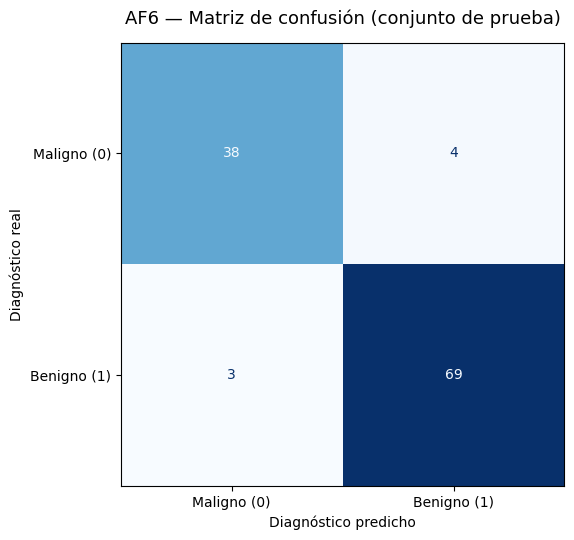

In [ ]:
matriz = confusion_matrix(test_label, predicciones, labels=[0, 1])
print("Matriz de confusión [Maligno, Benigno]:")
print(matriz)

fig_matriz, ax_matriz = plt.subplots(figsize=(7.2, 5.5))
display_matriz = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Maligno (0)", "Benigno (1)"]
)
display_matriz.plot(ax=ax_matriz, cmap="Blues", values_format="d", colorbar=False)
ax_matriz.set_title("AF6 — Matriz de confusión (conjunto de prueba)", fontsize=13, pad=13)
ax_matriz.set_xlabel("Diagnóstico predicho")
ax_matriz.set_ylabel("Diagnóstico real")
fig_matriz.tight_layout()
fig_matriz.savefig("AF6_Matriz_Confusion_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.2 Representación gráfica del árbol
Cada nodo muestra una condición de separación y la clase mayoritaria. Se utiliza `plot_tree`; el archivo final se guarda con **DPI = 300**, como solicita la actividad.

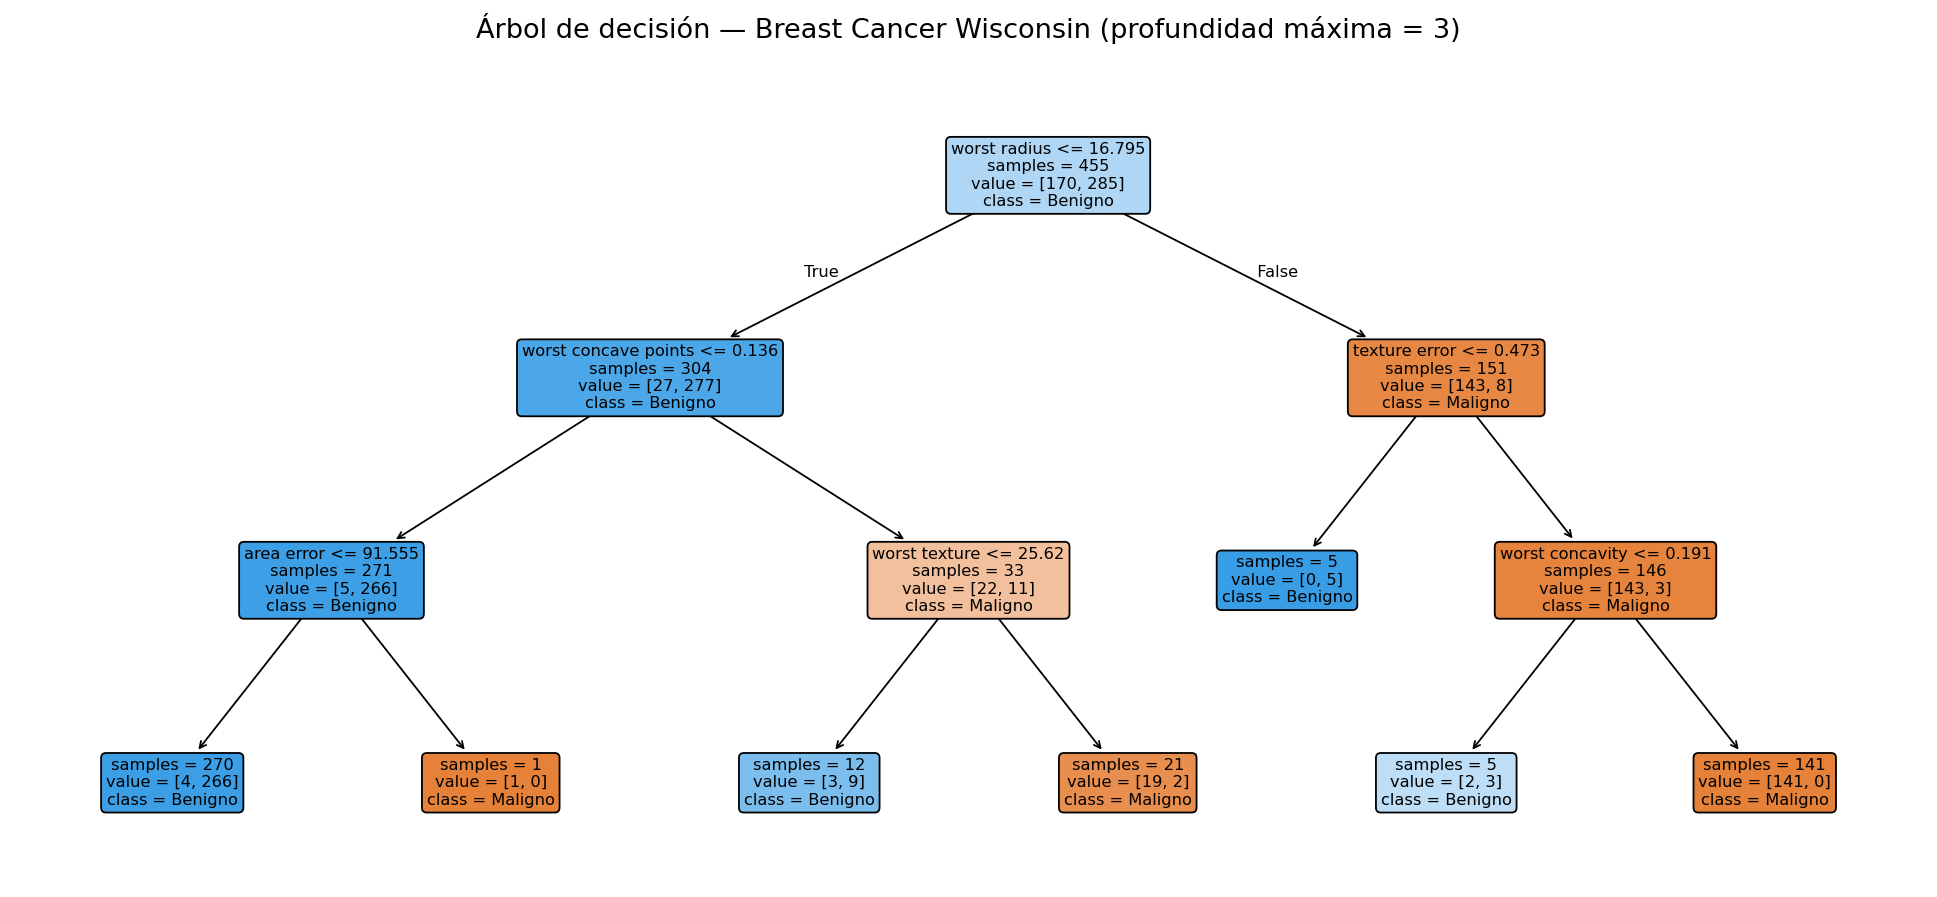

In [ ]:
fig_arbol, ax_arbol = plt.subplots(figsize=(15, 7), dpi=130)
plot_tree(
    modelo,
    feature_names=list(data.columns),
    class_names=["Maligno", "Benigno"],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=9,
    ax=ax_arbol
)
ax_arbol.set_title("Árbol de decisión — Breast Cancer Wisconsin (profundidad máxima = 3)", fontsize=15, pad=20)
fig_arbol.tight_layout()
fig_arbol.savefig("AF6_Arbol_Decision_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.3 Interpretación final
La exactitud indica qué proporción de los diagnósticos del conjunto de prueba coincidió con las etiquetas originales. Es importante revisar también los errores de la matriz de confusión: **clasificar un caso maligno como benigno** constituye un error especialmente relevante en este contexto. Esta práctica es educativa; el modelo no debe emplearse para efectuar diagnósticos médicos.

**Fuentes:** [Dataset en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) · [Visualización con `plot_tree`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html)